In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve,
                             precision_score, recall_score)

df = pd.read_csv("clinvar_2stars_AF_EVO.tsv", sep="\t")
df = df[df.has_AM & df.has_EVEE].copy()          # intersection, expect 56,085
df["gene"] = df["GENEINFO"].str.split("|").str[0].str.split(":").str[0]

y  = df["label"].to_numpy()
am = df["am_pathogenicity"].to_numpy()
ev = df["pathogenicity"].to_numpy()

# Point estimates
for name, s in [("AlphaMissense", am), ("EVEE", ev)]:
    print(name, "ROC-AUC", roc_auc_score(y, s),
          "PR-AUC", average_precision_score(y, s))
print("prevalence", y.mean())

# Gene-level cluster bootstrap, paired across the two tools
rng = np.random.default_rng(1)
groups = df.groupby("gene").indices
genes = np.array(list(groups.keys()))
rows = []
for _ in range(1000):
    pick = rng.choice(genes, size=len(genes), replace=True)
    i = np.concatenate([groups[g] for g in pick])
    yi = y[i]
    rows.append((roc_auc_score(yi, am[i]), roc_auc_score(yi, ev[i]),
                 average_precision_score(yi, am[i]),
                 average_precision_score(yi, ev[i])))
b = pd.DataFrame(rows, columns=["auc_am", "auc_ev", "ap_am", "ap_ev"])
b["d_auc"] = b.auc_ev - b.auc_am
b["d_ap"] = b.ap_ev - b.ap_am
print(b.quantile([0.025, 0.975]).T)             # 95% CIs, incl. paired differences

AlphaMissense ROC-AUC 0.959997188218894 PR-AUC 0.9394321371345797
EVEE ROC-AUC 0.9653952570822308 PR-AUC 0.9439948149804079
prevalence 0.37200677543015065
           0.025     0.975
auc_am  0.956019  0.963704
auc_ev  0.962420  0.968460
ap_am   0.928964  0.948039
ap_ev   0.934260  0.951770
d_auc   0.002702  0.008109
d_ap   -0.000134  0.009234


In [5]:
# Precision-recall curves
def thresholded(y, cls, pos, neg):
    called = cls.isin([pos, neg]).to_numpy()
    pred = (cls == pos).to_numpy().astype(int)
    out = {
        "coverage": called.mean(),
        # on called variants only
        "precision_P": precision_score(y[called], pred[called], zero_division=0),
        "recall_P_called": recall_score(y[called], pred[called]),
        # uncertain counted as missed
        "recall_P_all": recall_score(y, pred),
        # benign direction, by flipping labels
        "precision_B": precision_score(1 - y[called], 1 - pred[called]),
        "recall_B_all": recall_score(1 - y, ((cls == neg).to_numpy()).astype(int)),
    }
    return out

print(thresholded(y, df.am_class, "likely_pathogenic", "likely_benign"))
print(thresholded(y, df.evee_classification, "Likely_Pathogenic", "Likely_Benign"))

{'coverage': np.float64(0.9340287064277436), 'precision_P': 0.90127912531182, 'recall_P_called': 0.8888249149437321, 'recall_P_all': 0.81388995398773, 'precision_B': 0.9366801812544717, 'recall_B_all': 0.8920814286931092}
{'coverage': np.float64(0.7907640188998841), 'precision_P': 0.9678895400176607, 'recall_P_called': 0.8987030411449016, 'recall_P_all': 0.5778853527607362, 'precision_B': 0.957388768695325, 'recall_B_all': 0.8669259816586695}


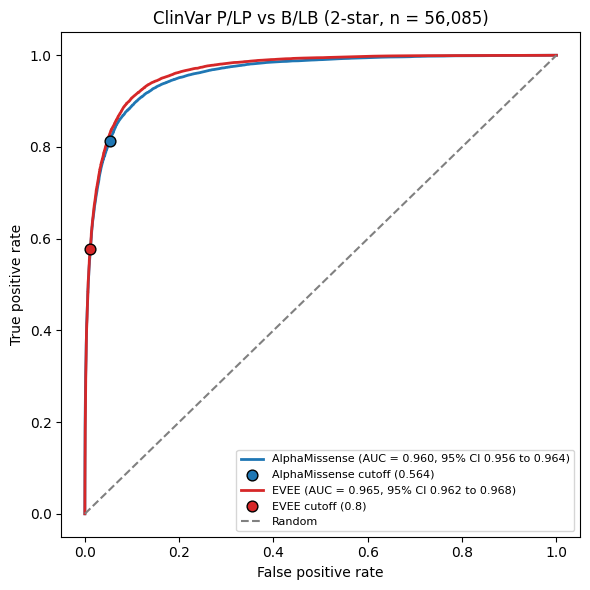

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

ci = b.quantile([0.025, 0.975])
tools = {"AlphaMissense": (am, "auc_am", 0.564, "tab:blue"),
         "EVEE":          (ev, "auc_ev", 0.80,  "tab:red")}

fig, ax = plt.subplots(figsize=(6, 6))
for name, (s, col, thr, color) in tools.items():
    fpr, tpr, _ = roc_curve(y, s)
    auc = roc_auc_score(y, s)
    lo, hi = ci[col]
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f"{name} (AUC = {auc:.3f}, 95% CI {lo:.3f} to {hi:.3f})")

    # operating point at the pathogenic cutoff
    pred = s >= thr
    ax.scatter((pred & (y == 0)).sum() / (y == 0).sum(),
               (pred & (y == 1)).sum() / (y == 1).sum(),
               s=60, color=color, edgecolor="black", zorder=3,
               label=f"{name} cutoff ({thr})")

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random")
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="ClinVar P/LP vs B/LB (2-star, n = 56,085)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("clinvar_AM_EVEE_roc.png", dpi=300)